/usr/local/lib/python3.12/dist-packages/pymc/distributions/timeseries.py:291: UserWarning: Initial distribution not specified, defaulting to `Normal.dist(0, 100)`.You can specify an init_dist manually to suppress this warning.
  warnings.warn(


Output()

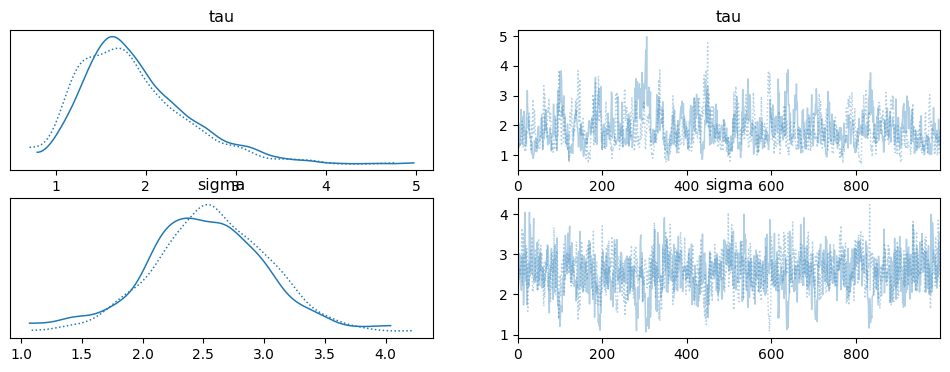

In [1]:
import numpy as np
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt

np.random.seed(42)

T = 40
true_tau = 1.5
true_sigma = 3.0

theta_true = np.zeros(T)
theta_true[0] = 50

for t in range(1, T):
    theta_true[t] = np.random.normal(theta_true[t-1], true_tau)

y = np.random.normal(theta_true, true_sigma)

with pm.Model() as model:
    tau = pm.HalfNormal("tau", 5)
    sigma = pm.HalfNormal("sigma", 5)

    theta = pm.GaussianRandomWalk(
        "theta",
        sigma=tau,
        shape=T
    )

    obs = pm.Normal(
        "obs",
        mu=theta,
        sigma=sigma,
        observed=y
    )

    trace = pm.sample(1000, tune=1000, target_accept=0.9)

az.plot_trace(trace, var_names=["tau", "sigma"])
plt.show()

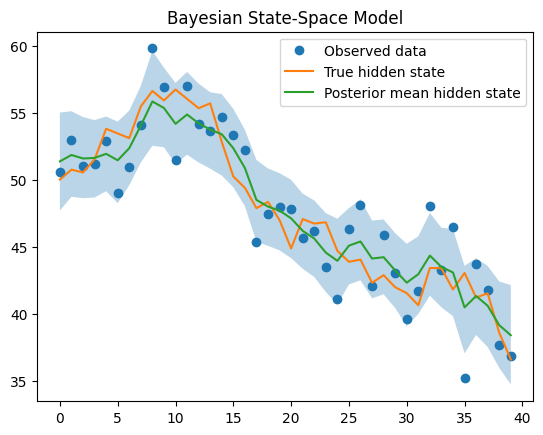

In [2]:
theta_samples = trace.posterior["theta"].stack(sample=("chain", "draw")).values

theta_mean = theta_samples.mean(axis=1)
theta_lower = np.percentile(theta_samples, 2.5, axis=1)
theta_upper = np.percentile(theta_samples, 97.5, axis=1)

plt.plot(y, "o", label="Observed data")
plt.plot(theta_true, label="True hidden state")
plt.plot(theta_mean, label="Posterior mean hidden state")
plt.fill_between(range(T), theta_lower, theta_upper, alpha=0.3)
plt.legend()
plt.title("Bayesian State-Space Model")
plt.show()